# King County House Prices: the 5-Minute Version

Predicting the sale price of a house in King County (Seattle and surroundings) with a tuned regression model. The full analysis, with every step and its reasoning, is in `02_king_county_project_dominic.ipynb`; this notebook shows the main decisions and figures. It recomputes everything with the hyperparameters found there (no new search), so it runs in a few seconds after `01_loading_the_data_dominic.ipynb` has created `data/eda.csv`.

Each section ends with **🗣 What to say** (about 30-40 seconds per section). The appendix collects questions to expect and short answers.

### Setup (not presented)

Same data, split, hand changes and pipelines as in notebook 02, with the tuned hyperparameters fixed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("data/eda.csv")
houses = df["house_id"].unique()
train_houses, test_houses = train_test_split(houses, test_size=0.2, random_state=42)   # split by house
df_train, df_test = df[df["house_id"].isin(train_houses)], df[df["house_id"].isin(test_houses)]
groups_train = df_train["house_id"]


def prepare(df):
    """Hand changes from notebook 02 (fixed rules, nothing learned)."""
    df = df.copy()
    df["sqft_basement"] = df["sqft_basement"].fillna(df["sqft_living"] - df["sqft_above"])
    sale_date = pd.to_datetime(df["date"])
    df["sale_year"], df["sale_month"] = sale_date.dt.year, sale_date.dt.month
    df["age_at_sale"] = (df["sale_year"] - df["yr_built"]).clip(lower=0)
    df["renovated"] = ((df["yr_renovated"] > 0) & (df["yr_renovated"] <= df["sale_year"])).astype(int)
    df["has_basement"] = (df["sqft_basement"] > 0).astype(int)
    return df.drop(columns=["id", "house_id", "id_details", "date", "sqft_above", "yr_built", "yr_renovated"])


train, test = prepare(df_train), prepare(df_test)
X_train, y_train = train.drop(columns="price"), train["price"]
X_test, y_test = test.drop(columns="price"), test["price"]

In [2]:
freq_cols, log_cols, zip_cols = ["waterfront", "view"], ["sqft_lot", "sqft_lot15"], ["zipcode"]
num_cols = [c for c in X_train.columns if c not in freq_cols + log_cols + zip_cols]


def numeric_part():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("freq", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("scale", StandardScaler())]), freq_cols),
        ("log", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())]), log_cols),
    ])


def make_model(alpha, degree=None, use_zipcode=True):
    numeric = numeric_part() if degree is None else Pipeline([
        ("prepare", numeric_part()), ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale", StandardScaler())])
    parts = [("numeric", numeric, num_cols + freq_cols + log_cols)]
    if use_zipcode:
        parts.append(("zip", OneHotEncoder(handle_unknown="ignore"), zip_cols))
    return Pipeline([("preprocess", ColumnTransformer(parts)), ("model", Ridge(alpha=alpha))])


cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
price_per_sqft = (y_train / X_train["sqft_living"]).median()                  # the rule baseline
models = {                                                                     # hyperparameters from notebook 02
    "mean baseline": DummyRegressor(strategy="mean").fit(X_train, y_train),
    "M1: Ridge": make_model(alpha=0.08835084701473975).fit(X_train, y_train),
    "M2: polynomial Ridge (best)": make_model(alpha=7.45934328572655, degree=2).fit(X_train, y_train),
    "M3: M2 on log(price)": make_model(alpha=1, degree=2).fit(X_train, np.log(y_train)),
}
predict = {
    "mean baseline": models["mean baseline"].predict,
    "rule baseline": lambda X: price_per_sqft * X["sqft_living"],
    "M1: Ridge": models["M1: Ridge"].predict,
    "M2: polynomial Ridge (best)": models["M2: polynomial Ridge (best)"].predict,
    "M3: M2 on log(price)": lambda X: np.exp(models["M3: M2 on log(price)"].predict(X)),
}
print(f"train {X_train.shape}, test {X_test.shape}, rule: ${price_per_sqft:,.2f} per sqft")

train (17270, 20), test (4327, 20), rule: $245.10 per sqft


## 1. Question and Metric

- **Task:** predict the sale price of a house from its attributes and beat two baselines.
- **Metric: RMSE in dollars.** I assume a bank lends money based on the estimated value: overestimating one villa by $500k costs far more than many small errors, and RMSE squares the errors, so large ones weigh more. MAE and R² are reported alongside.
- The metric was fixed **before** looking at the data.

> **🗣 What to say:** "The question is: how well can we estimate the price of a house in King County? I chose the RMSE in dollars as my metric, because I imagine a bank using the estimate for a loan, and for a bank one large mistake on an expensive house is worse than many small ones. RMSE punishes large errors more than MAE does. I decided this before looking at the data."

## 2. Data and Split

- Two tables merged on the house key: **21,597 sales** of **21,420 houses**, May 2014 to May 2015 (`how="left"` keeps every sale; no house was missing).
- **176 houses were sold more than once.** A row-wise split would put 63 of them into both sets, so the model would be tested on houses it had seen with a price. I therefore **split by house** (80/20: 17,270 training and 4,327 test sales) and used **`GroupKFold`** in cross-validation for the same reason.
- The test set stayed untouched until the very end.

> **🗣 What to say:** "The data came in two tables, sales and houses, which I merged on the house id. Some houses were sold twice, so I split the data by house, not by sale: otherwise the model could have seen the same house with its price in training and then again in the test. For the same reason I used GroupKFold in cross-validation."

## 3. What the Exploration Showed

![Map of King County with every sale coloured by price: the expensive houses lie around Lake Washington and Bellevue](assets/king_county_price_map.png)

- **The price is strongly right-skewed:** median $450,000, mean $542,000, up to $7.7 million.
- **`sqft_living` is the strongest single feature** (Pearson 0.70), so the rule baseline is "median price per square foot × living area" ($245 per sqft).
- **The zip code** has a correlation of almost 0 with the price, but the **highest mutual information** (0.41): its numbers are labels without an order, yet the location decides the price (median per zip code from $230,000 to $1.9 million). So it is one-hot encoded.
- Hand changes, applied to train and test alike: basement area filled exactly, age at sale, "renovated" only if before the sale (5 houses were renovated *after* it), redundant columns dropped (`sqft_above`, `yr_built`).

> **🗣 What to say:** "Three findings shaped the model. The price is very skewed, a few villas cost millions. Living area is the strongest single feature, so my simple rule baseline is the price per square foot. And the zip code: its correlation with the price is zero, because zip codes are just labels, but it tells us more about the price than any other column. The map shows why: location matters. So the zip code goes into the model one-hot encoded."

## 4. Pipeline and Models

| Columns | In the pipeline |
|:--|:--|
| `waterfront`, `view` | most-frequent imputation, scaling |
| `sqft_lot`, `sqft_lot15` (skew 13 and 10) | `log1p`, scaling |
| other numeric columns | median imputation, scaling |
| `zipcode` | one-hot encoding |

- **M1:** Ridge on these features. **M2:** Ridge on degree-2 polynomial features of the numeric columns (not of the zip codes) plus the zip codes. **M3:** M2 trained on `log(price)`.
- Each tuned on the training set only: a wide `RandomizedSearchCV`, then a narrow `GridSearchCV`, 5-fold `GroupKFold`.

> **🗣 What to say:** "Everything that learns from the data sits in one pipeline, so in cross-validation it is fitted on the training folds only. I tuned three Ridge models: plain, with polynomial features, and the polynomial one on the logarithm of the price."

## 5. What Each Step Changed

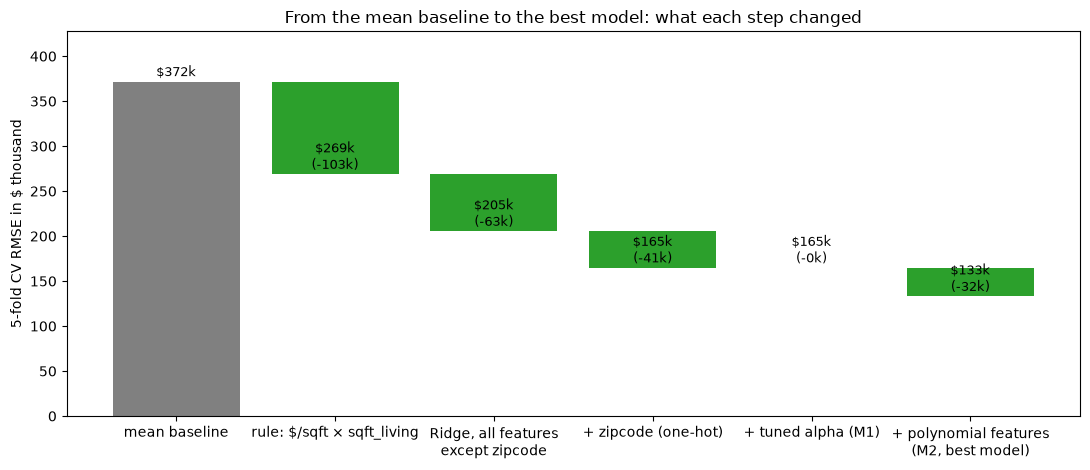

In [3]:
def cv_rmse(model, log_target=False):
    scores = []
    for tr, va in cv.split(X_train, y_train, groups=groups_train):
        if model == "rule":
            rate = (y_train.iloc[tr] / X_train["sqft_living"].iloc[tr]).median()
            pred = rate * X_train["sqft_living"].iloc[va]
        else:
            model.fit(X_train.iloc[tr], y_train.iloc[tr])
            pred = model.predict(X_train.iloc[va])
        scores.append(root_mean_squared_error(y_train.iloc[va], pred))
    return np.mean(scores) / 1e3


steps = pd.Series({
    "mean baseline": cv_rmse(DummyRegressor()),
    "rule: $/sqft × sqft_living": cv_rmse("rule"),
    "Ridge, all features\nexcept zipcode": cv_rmse(make_model(alpha=1.0, use_zipcode=False)),
    "+ zipcode (one-hot)": cv_rmse(make_model(alpha=1.0)),
    "+ tuned alpha (M1)": cv_rmse(make_model(alpha=0.08835084701473975)),
    "+ polynomial features\n(M2, best model)": cv_rmse(make_model(alpha=7.45934328572655, degree=2)),
})
gain = steps.diff().fillna(steps.iloc[0])
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(steps.index, gain.abs(), bottom=[0] + list(steps.iloc[1:]), color=["grey"] + ["tab:green"] * 5)
for i, (level, g) in enumerate(zip(steps, gain)):
    ax.text(i, level + 6, f"${level:,.0f}k" if i == 0 else f"${level:,.0f}k\n({g:+,.0f}k)", ha="center", fontsize=9)
ax.set_ylabel("5-fold CV RMSE in $ thousand")
ax.set_ylim(0, steps.max() * 1.15)
ax.set_title("From the mean baseline to the best model: what each step changed")
plt.tight_layout()
plt.show()

**Choosing the best model:** M3 (log target) had a slightly lower mean CV error ($127,038) than M2 ($133,103), but its folds spread almost three times as much (sd $16,933 against $6,153). M2 lies within one standard error of M3 ($16,933 / √5 ≈ $7,573), so by the **one-standard-error rule** I chose the simpler and more stable **M2**, before touching the test set.

> **🗣 What to say:** "This chart is the story of the project. The simple rule already removes more than a quarter of the error. Then the features, the zip code and the polynomial features each bring a big step. Tuning the penalty brought nothing at all: with 17,000 sales, Ridge hardly needs it. Between my two best models I chose M2, because the log model was only slightly better on average but much less stable, and the one-standard-error rule says: take the simpler one."

## 6. One Test, All Models

In [4]:
rows = {}
for name, f in predict.items():
    p_tr, p_te = f(X_train), f(X_test)
    rows[name] = {"train RMSE": f"${root_mean_squared_error(y_train, p_tr):,.0f}",
                  "test RMSE": f"${root_mean_squared_error(y_test, p_te):,.0f}",
                  "test MAE": f"${mean_absolute_error(y_test, p_te):,.0f}",
                  "train R²": f"{r2_score(y_train, p_tr):.3f}", "test R²": f"{r2_score(y_test, p_te):.3f}"}
pd.DataFrame(rows).T

,train RMSE,test RMSE,test MAE,train R²,test R²
mean baseline,"$372,183","$347,480","$230,880",0.000,-0.001
rule baseline,"$268,971","$250,933","$164,736",0.478,0.478
M1: Ridge,"$163,637","$144,988","$94,323",0.807,0.826
M2: polynomial Ridge (best),"$124,152","$119,652","$75,578",0.889,0.881
M3: M2 on log(price),"$115,266","$113,621","$67,809",0.904,0.893


> **🗣 What to say:** "On the test set, used exactly once, every model beats both baselines. My best model M2 has a test RMSE of about $120,000 and explains 88% of the price variation, half the error of the rule. All test errors are lower than the training errors, even the mean baseline's: the test set simply contains fewer extreme villas. The training and test R² of M2 are almost equal, so it does not overfit. M3 was a bit better on the test set too, but I had chosen M2 before, and choosing again now would misuse the test set."

## 7. Where the Best Model Is Wrong

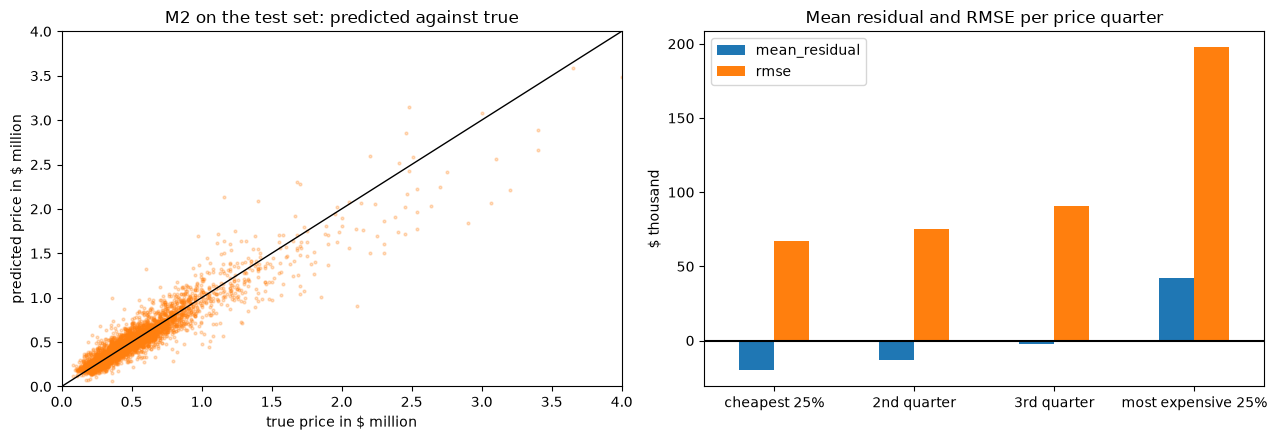

waterfront: 23 houses, RMSE $447,214 vs $115,431 for the others
the largest 5% of the errors make up 61% of the squared error


In [5]:
pred = models["M2: polynomial Ridge (best)"].predict(X_test)
residual = y_test - pred                                   # positive: price underestimated
quarter = pd.qcut(y_test, q=4, labels=["cheapest 25%", "2nd quarter", "3rd quarter", "most expensive 25%"])
by_quarter = residual.groupby(quarter, observed=True).agg(
    mean_residual="mean", rmse=lambda r: np.sqrt((r ** 2).mean())) / 1e3

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test / 1e6, pred / 1e6, s=4, alpha=0.25, color="tab:orange")
axes[0].plot([0, 4], [0, 4], color="black", lw=1)
axes[0].set(xlim=(0, 4), ylim=(0, 4), xlabel="true price in $ million", ylabel="predicted price in $ million",
            title="M2 on the test set: predicted against true")
by_quarter.plot.bar(ax=axes[1], rot=0)
axes[1].axhline(0, color="black")
axes[1].set(ylabel="$ thousand", xlabel="", title="Mean residual and RMSE per price quarter")
plt.tight_layout()
plt.show()

waterfront = test["waterfront"] == 1
print(f"waterfront: {waterfront.sum()} houses, RMSE ${np.sqrt((residual[waterfront] ** 2).mean()):,.0f} "
      f"vs ${np.sqrt((residual[~waterfront] ** 2).mean()):,.0f} for the others")
sq = (residual ** 2).sort_values(ascending=False)
print(f"the largest 5% of the errors make up {sq.head(len(sq) // 20).sum() / sq.sum():.0%} of the squared error")

> **🗣 What to say:** "Where is it wrong? For ordinary houses, it is typically 10 to 15 percent off. The big errors are luxury houses: on the right of the scatter plot the dots fall below the line, so expensive houses are underestimated, by $42,000 on average in the top quarter, while cheap ones are slightly overestimated: the model pulls towards the average. Waterfront houses have an error four times as large as the others, and the largest 5% of the errors make up 61% of the squared error. These are rare houses in the training data, and what makes them special, like the plot or the interior, is not in the data."

## 8. Conclusion

- **Best model:** Ridge on degree-2 polynomial features plus one-hot zip codes. **Test RMSE $119,652, MAE $75,578, R² 0.881**, half the error of the rule baseline, no overfitting.
- **What made the difference:** the location (zip code) and the polynomial features, not tuning the penalty.
- **Limits:** expensive and waterfront houses are underestimated; the test set is easier than the training set; the log model may be slightly better and is worth a closer look.

> **🗣 What to say:** "To sum up: a tuned Ridge with polynomial features and the zip code estimates house prices with a typical error of about $120,000, half of the simple rule's. What mattered was good features, especially the location. Its weak spot is luxury and waterfront houses. Thank you."

---

## Appendix: Questions to Expect

**Why RMSE and not MAE?** Because a large error is costly in my scenario (a bank lending on the estimate). RMSE squares the errors, so one $500k miss weighs more than five $100k misses; MAE would count them the same. MAE and R² are reported alongside.

**Why split by house?** 176 houses were sold more than once. With a row-wise split, 63 of them would be in both sets, and the model would be tested on houses it had already seen with a price: mild leakage. For the same reason, cross-validation uses `GroupKFold`.

**Why not just `KFold` in cross-validation, after the house split?** Then the same house could be in a training fold and its validation fold, so the model choice would be slightly too optimistic, even though the test set is clean.

**What goes into `prepare()` and what into the pipeline?** Rules that can be calculated for one house alone, without knowing the others (basement = living − above, age at sale), go into `prepare()`. Everything that learns from many rows (median, most frequent value, mean and spread for scaling, the list of zip codes) goes into the pipeline, so that it is learned on the training part only, in every fold.

**Why does the zip code have a correlation of 0 but the highest mutual information?** The zip codes are labels without an order, so no straight line runs through them; mutual information only asks whether the groups have different prices, and they do (by a factor of 8). Cross-validation confirmed that it adds information on top of size and quality (−$40,600).

**Why was `sqft_above` dropped?** `sqft_living = sqft_above + sqft_basement` exactly, so the three columns had an infinite VIF; dropping `sqft_above` loses no information. The same holds for `yr_built` once `age_at_sale` exists.

**Why did tuning `alpha` change nothing for M1?** With 17,270 sales and 89 features there is little overfitting to hold back, so the curve is flat over many orders of magnitude. The gain came from better features.

**Why degree 2 and not 3?** Degree 3 creates 1,539 features and was worse for every `alpha` (about $147,000): it starts to fit noise.

**The best `alpha` of M2 was on the edge of the grid. Isn't that a problem?** Normally it means "extend the grid". Here the curve is flat (less than $1,000 over three orders of magnitude), so the one-standard-error rule picks the strongest penalty within one standard error of the best: `alpha` 7.46.

**Why M2 and not M3, which was better on the test set?** The choice was made before the test, with cross-validation: M3's lower mean was not reliable (its folds spread three times as much; M2 lies within one standard error of M3), and M2 is simpler. Choosing again on the test set would turn it into a validation set.

**Why are all test errors lower than the training errors?** The test set is easier: even the mean baseline is better there, and its RMSE equals the spread of the prices. R², which accounts for the spread, shows almost no gap for M2 (0.889 vs. 0.881).

**What could reduce the errors on expensive houses?** A log target (M3 points that way), logs of further area columns, interactions with `waterfront` and `grade`; tree-based models from week 4 could capture such special cases better.